In [46]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, SymLogNorm
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({"font.size" : 15,
                     "figure.dpi" : 100, 
                     "grid.alpha" : 0.3, 
                     "axes.grid": False, 
                     "axes.axisbelow" : True,
                     "figure.figsize":(8,6),
                     "mathtext.fontset":"cm",
                     "xtick.labelsize": 14,
                     "ytick.labelsize": 14,
                     "axes.labelsize": 16, 
                     "legend.fontsize": 13.5})
plt.rc("text", usetex=False)
plt.rc("font", family="serif")

In [19]:
# results directory
data_dir = "../data/sweep_2026_02_24_1548/"

# load data
sims_df = pd.read_feather(f"{data_dir}simulations.arrow")
cascades_df = pd.read_feather(f"{data_dir}cascades.arrow")
nodes_df = pd.read_feather(f"{data_dir}nodes.arrow")
edges_df = pd.read_feather(f"{data_dir}edges.arrow")

print(f"Loaded {len(cascades_df):,} cascades!")

Loaded 1,000,000 cascades!


In [76]:
def plot_parameter_interaction(df, x_col, y_col, x_label, y_label, gridsize=10):
    """
    Plots Hexbin maps for Fake Cascades, True Cascades, and Welfare.
    """
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # 1. Fake Cascade Size
    hb1 = axes[0].hexbin(df[x_col], df[y_col], C=df['avg_fake_cascade'], 
                         reduce_C_function=np.mean, gridsize=gridsize, cmap='Reds')
    axes[0].set_title('Avg Fake Cascade Size (% of Net)', fontsize=14)
    axes[0].set_xlabel(x_label, fontsize=12)
    axes[0].set_ylabel(y_label, fontsize=12)
    cb1 = fig.colorbar(hb1, ax=axes[0])
    
    # 2. True Cascade Size
    hb2 = axes[1].hexbin(df[x_col], df[y_col], C=df['avg_true_cascade'], 
                         reduce_C_function=np.mean, gridsize=gridsize, cmap='Greens')
    axes[1].set_title('Avg True Cascade Size (% of Net)', fontsize=14)
    axes[1].set_xlabel(x_label, fontsize=12)
    cb2 = fig.colorbar(hb2, ax=axes[1])
    
    # 3. Social Welfare (Requires TwoSlopeNorm to perfectly center White at 0)
    vmin, vmax = df['avg_welfare'].min(), df['avg_welfare'].max()
    
    # Fallback in case the data is entirely positive or entirely negative
    if vmin >= 0: vmin = -0.1
    if vmax <= 0: vmax = 0.1
        
    norm = TwoSlopeNorm(
        vmin=vmin,
        vcenter=0,
        vmax=vmax,
    )

    hb3 = axes[2].hexbin(df[x_col], df[y_col], C=df['avg_welfare'], 
                         reduce_C_function=np.mean, gridsize=gridsize, cmap='RdBu', norm=norm)
    axes[2].set_title('Avg Social Welfare', fontsize=14)
    axes[2].set_xlabel(x_label, fontsize=12)
    cb3 = fig.colorbar(hb3, ax=axes[2])
    
    plt.tight_layout()
    plt.show()

In [77]:
sims_df.head()

,global_sim_id,lhs_id,rep_id,cost,rep_gain,rep_loss,verif_tpr,verif_fpr,fake_prob,num_conn,avg_welfare,avg_fake_cascade,avg_true_cascade,avg_verify_rate
0,1,1,1,3.183957,0.944291,1.990938,0.940778,0.099764,0.748459,2,0.115593,0.000045,0.000265,0.000000
1,2,1,2,3.183957,0.944291,1.990938,0.940778,0.099764,0.748459,2,-4.947863,0.000838,0.000769,0.000000
2,3,1,3,3.183957,0.944291,1.990938,0.940778,0.099764,0.748459,2,-38.002020,0.002487,0.002667,0.000047
3,4,1,4,3.183957,0.944291,1.990938,0.940778,0.099764,0.748459,2,-7.696050,0.000930,0.000310,0.000000
4,5,1,5,3.183957,0.944291,1.990938,0.940778,0.099764,0.748459,2,-0.589655,0.000186,0.000267,0.000000


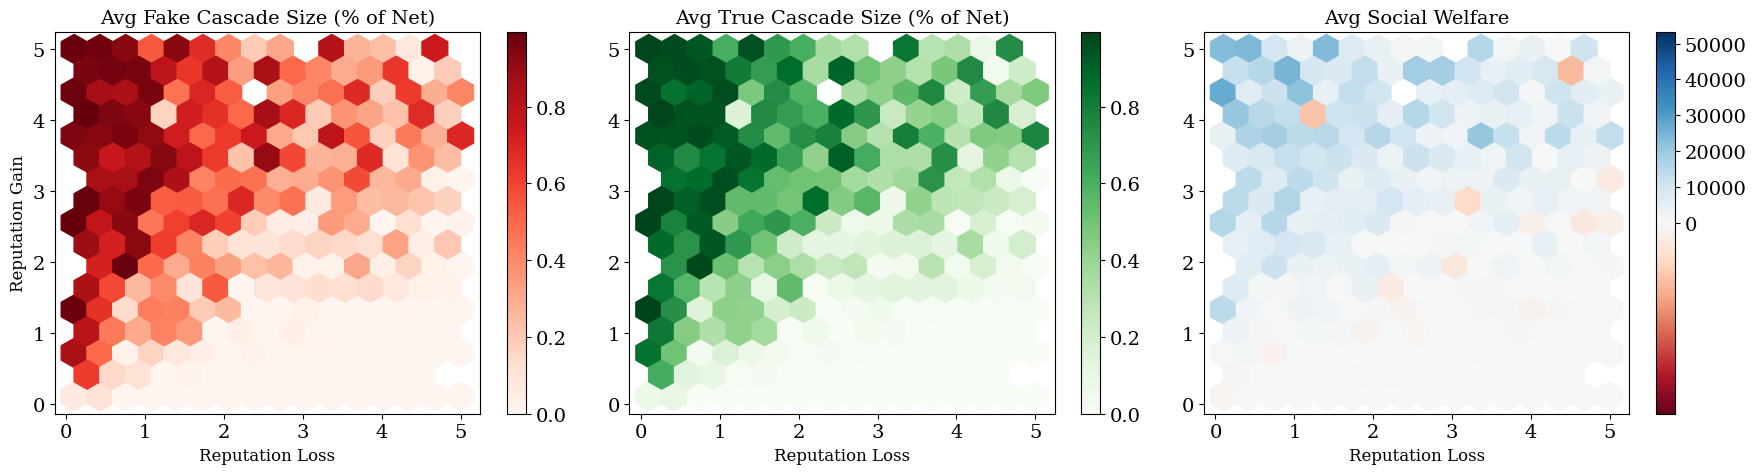

In [78]:
plot_parameter_interaction(
    sims_df,
    x_col='rep_loss',
    x_label='Reputation Loss', 
    y_col='rep_gain', 
    y_label='Reputation Gain',
    gridsize=15
)

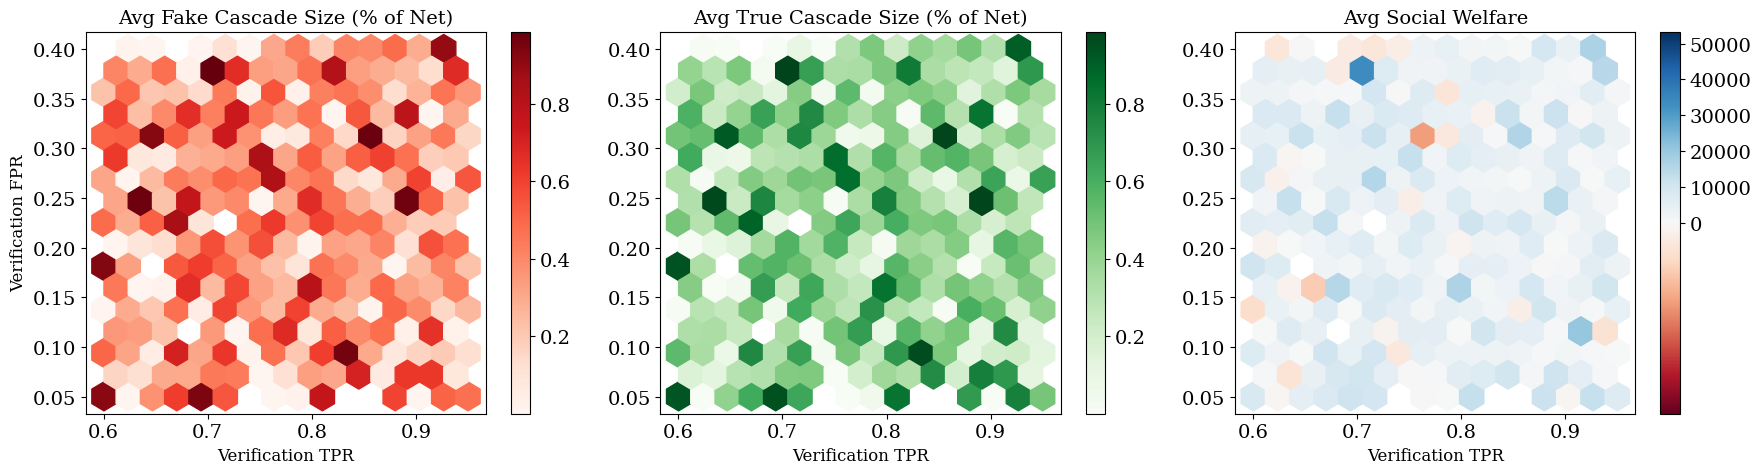

In [83]:
plot_parameter_interaction(
    sims_df,
    x_col='verif_tpr',
    x_label='Verification TPR', 
    y_col='verif_fpr', 
    y_label='Verification FPR',
    gridsize=15
)

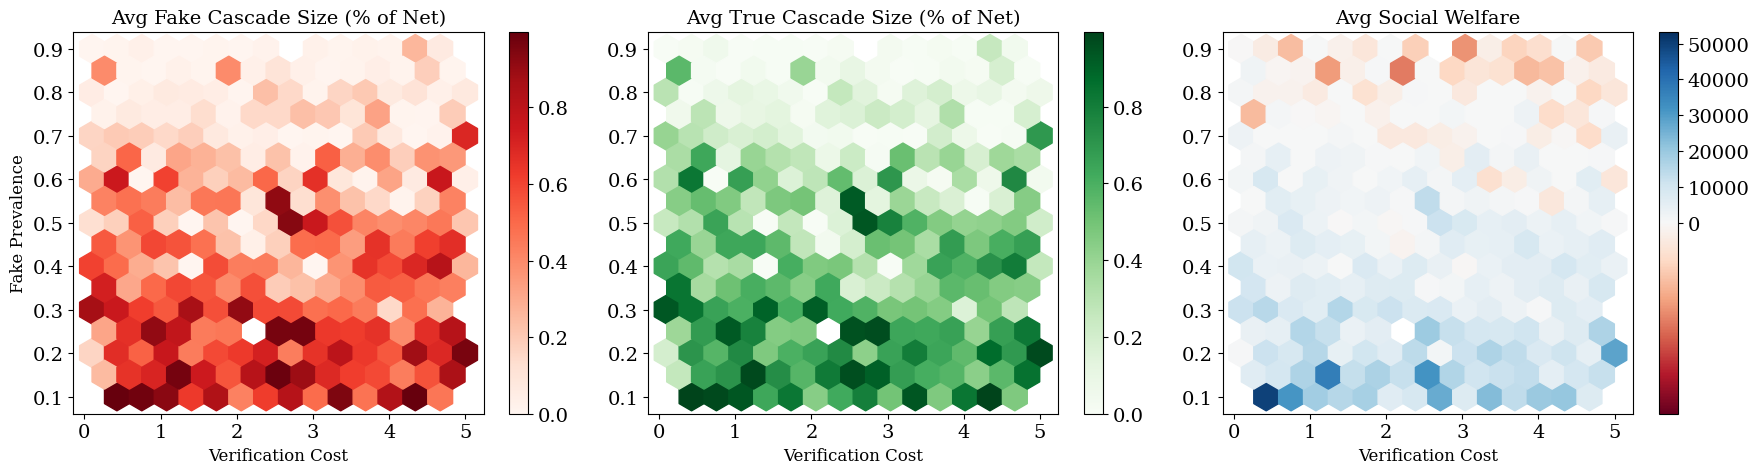

In [81]:
plot_parameter_interaction(
    sims_df, 
    x_col='cost',
    x_label='Verification Cost', 
    y_col='fake_prob', 
    y_label='Fake Prevalence',
    gridsize=15
)